<a href="https://colab.research.google.com/github/carminenasti2001/Ecopulse/blob/main/Ecopulse_livello_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"
parametri = {
    "latitude": 41.9,
    "longitude": 12.5,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "hourly": "temperature_2m,shortwave_radiation,wind_speed_10m,cloud_cover",
    "wind_speed_unit": "ms",
    "timezone": "Europe/Rome",
}
risposta = requests.get(url, params=parametri)
meteo = pd.DataFrame(risposta.json()["hourly"])
print(meteo.shape)
print(meteo.head())
meteo["time"] = pd.to_datetime(meteo["time"])

(8760, 5)
               time  temperature_2m  shortwave_radiation  wind_speed_10m  \
0  2025-01-01T00:00             5.3                  0.0            1.25   
1  2025-01-01T01:00             5.1                  0.0            1.42   
2  2025-01-01T02:00             4.3                  0.0            1.66   
3  2025-01-01T03:00             3.5                  0.0            1.57   
4  2025-01-01T04:00             3.2                  0.0            1.92   

   cloud_cover  
0           38  
1           41  
2           19  
3           32  
4          100  


count    8760.000000
mean       75.225367
std       102.136499
min         0.000000
25%         0.000000
50%         4.168294
75%       145.609707
max       363.041587
Name: kwh, dtype: float64
Produzione annua (MWh): 659


<Axes: xlabel='time'>

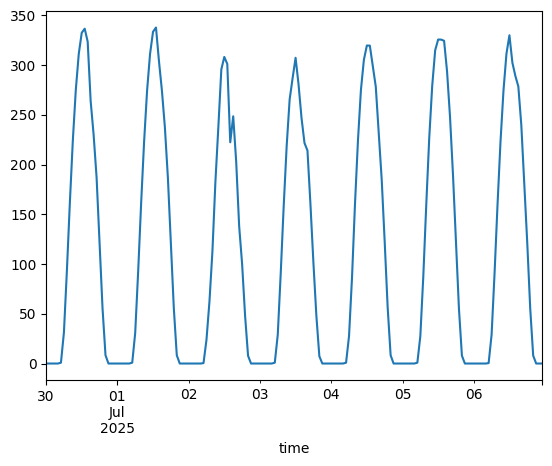

In [8]:
meteo["time"] = pd.to_datetime(meteo["time"])

# Temperatura delle celle: i pannelli si scaldano col sole e perdono resa
meteo["temp_cella"] = meteo["temperature_2m"] + 0.025 * meteo["shortwave_radiation"]

# Produzione oraria (kWh): potenza x irraggiamento x rendimento x correzione temperatura
meteo["kwh"] = (500 * (meteo["shortwave_radiation"] / 1000) * 0.85
                * (1 - 0.004 * (meteo["temp_cella"] - 25)))
meteo["kwh"] = meteo["kwh"].clip(lower=0)

print(meteo["kwh"].describe())
print("Produzione annua (MWh):", round(meteo["kwh"].sum() / 1000))

# Una settimana d'estate, per vedere le campane giornaliere
meteo.set_index("time")["kwh"].iloc[24*180 : 24*187].plot()

# EcoPulse AI – Previsione della produzione fotovoltaica Valuto se un modello di Machine Learning (Random Forest) prevede la produzione oraria di un impianto fotovoltaico ipotetico da 500 kWp meglio della baseline "domani = oggi". Dati meteo reali di Roma (Open-Meteo, anno 2025).La produzione è calcolata da una formula, non misurata. Progetto sviluppato con l'IA come tutor.



In [9]:
# EcoPulse AI – Previsione della produzione fotovoltaica Valuto se un modello di Machine Learning (Random Forest) prevede la produzione oraria di un impianto fotovoltaico ipotetico da 500 kWp meglio della baseline "domani = oggi". Dati meteo reali di Roma (Open-Meteo, anno 2025).La produzione è calcolata da una formula, non misurata. Progetto sviluppato con l'IA come tutor.
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

meteo["ora"] = meteo["time"].dt.hour
giorno = meteo["time"].dt.dayofyear

# Stagione come cerchio: il 31 dicembre diventa vicino al 1° gennaio
meteo["giorno_sin"] = np.sin(2 * np.pi * giorno / 365)
meteo["giorno_cos"] = np.cos(2 * np.pi * giorno / 365)

# Altezza del sole dalla geometria (0 di notte, 1 con sole allo zenit)
decl = 23.45 * np.sin(np.radians(360 * (284 + giorno) / 365))
angolo = 15 * (meteo["ora"] - 12)
lat = np.radians(41.9)
meteo["sole"] = (np.sin(lat) * np.sin(np.radians(decl))
                 + np.cos(lat) * np.cos(np.radians(decl)) * np.cos(np.radians(angolo))).clip(lower=0)

meteo["kwh_ieri"] = meteo["kwh"].shift(24)
dati = meteo.dropna().reset_index(drop=True)

taglio = int(len(dati) * 0.8)
train = dati.iloc[:taglio]
test = dati.iloc[taglio:]
mae_base = mean_absolute_error(test["kwh"], test["kwh_ieri"])

def prova(colonne):
    modello = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
    modello.fit(train[colonne], train["kwh"])
    return mean_absolute_error(test["kwh"], modello.predict(test[colonne]))

base_col = ["temperature_2m", "wind_speed_10m", "cloud_cover", "kwh_ieri"]
print("domani = oggi:", round(mae_base, 1))
print("con stagione ciclica:", round(prova(base_col + ["ora", "giorno_sin", "giorno_cos"]), 1))
print("con altezza del sole:", round(prova(base_col + ["sole"]), 1))


domani = oggi: 9.2
con stagione ciclica: 9.4
con altezza del sole: 8.1


## Risultati e limiti Test su fine ottobre–dicembre 2025. Errore medio orario: "domani = oggi" 9,2 kWh; Random Forest con stagione ciclica 9,4 kWh;con altezza del sole 9,9 kWh. Il modello non batte la baseline.Limiti: produzione calcolata e non misurata; meteo osservato al posto delle previsioni; la nuvolosità è un indicatore grezzo dell'irraggiamento.Sviluppi: previsioni di irraggiamento archiviate, prezzi reali (GME), produzione reale (ENTSO-E/Terna).
